# Segmentación de jugadores en línea (Clustering)
Argenida Yehizabeth Pedraza Peñaranda

**Objetivo descriptivo:** segmentar a los usuarios en arquetipos según su nivel de actividad, progresión y patrones de compra, para apoyar estrategias personalizadas de monetización y contenido.


In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RS = 42

# En Colab: sube el CSV limpio al panel de archivos o ajusta la ruta
PATH = 'online_gaming_behavior_dataset.csv'
if not os.path.exists(PATH):
    PATH = '/mnt/user-data/uploads/online_gaming_behavior_dataset.csv'
df = pd.read_csv(PATH)
print(df.shape, '| nulos:', df.isna().sum().sum(), '| duplicados:', df.duplicated().sum())
df.head()

(40034, 13) | nulos: 0 | duplicados: 0


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


## Transformaciones
- **Variables de agrupamiento:** actividad (`PlayTimeHours`, `SessionsPerWeek`, `AvgSessionDurationMinutes`), progresión (`PlayerLevel`, `AchievementsUnlocked`) y compras (`InGamePurchases`).
- `EngagementLevel`, edad, género, ubicación, tipo de juego y dificultad **no** se usan para agrupar; solo sirven para perfilar los grupos.
- Se **estandarizan** las variables porque K-Means y GMM son sensibles a la escala. No se aplica balanceo, porque en clustering no hay variable objetivo.

In [3]:
feats = ['PlayTimeHours','SessionsPerWeek','AvgSessionDurationMinutes','PlayerLevel','AchievementsUnlocked','InGamePurchases']
scaler = StandardScaler()
X = scaler.fit_transform(df[feats])
pca = PCA(2, random_state=RS); Z = pca.fit_transform(X)   # solo para visualizar
print('Varianza explicada PCA 2D:', pca.explained_variance_ratio_.round(3), '=', pca.explained_variance_ratio_.sum().round(3))

Varianza explicada PCA 2D: [0.169 0.168] = 0.337


## Modelamiento

### Selección de k (K-Means)

,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,200165.393,0.237,1.753,8007.506
3,176018.151,0.160,2.071,7298.746
4,161546.170,0.144,1.877,6497.008
5,149694.459,0.144,1.795,6050.715
6,141009.598,0.142,1.604,5631.669
7,133280.154,0.143,1.467,5351.988
8,127158.534,0.148,1.695,5083.406


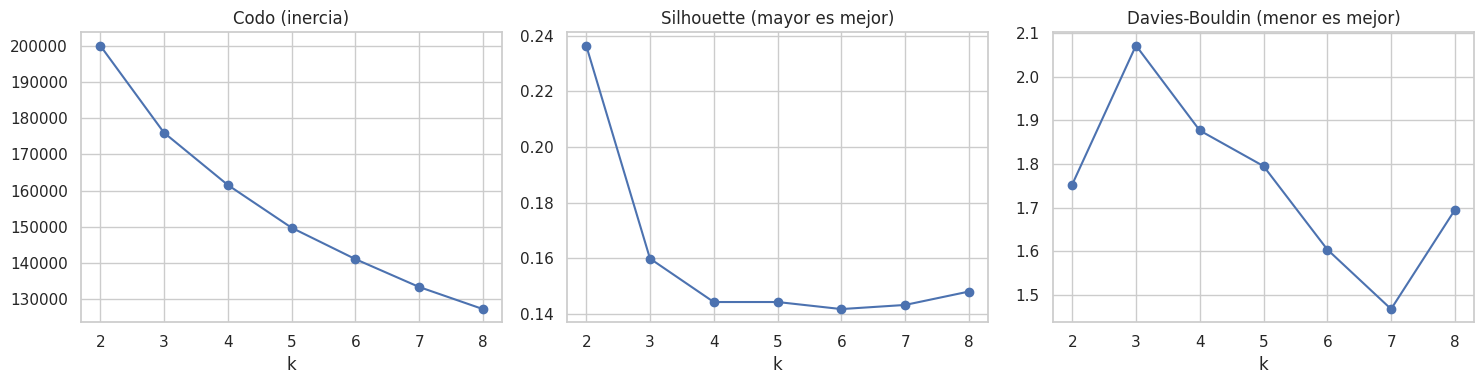

In [4]:
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=RS).fit(X)
    rows.append(dict(k=k, inercia=km.inertia_,
        silhouette=silhouette_score(X, km.labels_, sample_size=10000, random_state=RS),
        davies_bouldin=davies_bouldin_score(X, km.labels_),
        calinski_harabasz=calinski_harabasz_score(X, km.labels_)))
sel = pd.DataFrame(rows).set_index('k')
display(sel.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sel.inercia.plot(marker='o', ax=axes[0], title='Codo (inercia)')
sel.silhouette.plot(marker='o', ax=axes[1], title='Silhouette (mayor es mejor)')
sel.davies_bouldin.plot(marker='o', ax=axes[2], title='Davies-Bouldin (menor es mejor)')
plt.tight_layout(); plt.show()

**Lectura:** k=2 tiene el silhouette más alto, pero solo separa compradores de no compradores (la variable binaria domina la distancia) y no sirve para segmentar. El codo es gradual y desde k=5 el silhouette se estabiliza. Se elige **k=5** por interpretabilidad de negocio y se contrasta con otros algoritmos.

### Comparación de algoritmos (k=5)

In [5]:
K = 5
models = {'K-Means': KMeans(K, n_init=20, random_state=RS).fit(X),
          'GMM': GaussianMixture(K, n_init=3, random_state=RS).fit(X)}
labels = {'K-Means': models['K-Means'].labels_, 'GMM': models['GMM'].predict(X)}
idx = np.random.RandomState(RS).choice(len(X), 8000, replace=False)   # Ward es O(n^2): se usa una muestra
agg_s = AgglomerativeClustering(K, linkage='ward').fit_predict(X[idx])
res = []
for n, l in labels.items():
    res.append(dict(modelo=n, silhouette=silhouette_score(X, l, sample_size=10000, random_state=RS),
                    davies_bouldin=davies_bouldin_score(X, l), calinski_harabasz=calinski_harabasz_score(X, l),
                    tamano_min=np.bincount(l).min(), tamano_max=np.bincount(l).max()))
res.append(dict(modelo='Jerárquico Ward (muestra 8k)', silhouette=silhouette_score(X[idx], agg_s),
                davies_bouldin=davies_bouldin_score(X[idx], agg_s), calinski_harabasz=calinski_harabasz_score(X[idx], agg_s),
                tamano_min=np.bincount(agg_s).min(), tamano_max=np.bincount(agg_s).max()))
pd.DataFrame(res).set_index('modelo').round(3)

,silhouette,davies_bouldin,calinski_harabasz,tamano_min,tamano_max
modelo,,,,,
K-Means,0.145,1.791,6065.677,7919,8065
GMM,0.141,1.889,5955.340,7884,8188
Jerárquico Ward (muestra 8k),0.096,2.105,958.105,822,2360


### Modelo final: K-Means (k=5) y perfilado de arquetipos

In [6]:
km = models['K-Means']
df['cluster'] = km.labels_
prof = df.groupby('cluster')[feats + ['Age']].mean()
prof['n'] = df.groupby('cluster').size()
prof['%'] = (prof.n / len(df) * 100).round(1)
prof.round(2)

,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,InGamePurchases,Age,n,%
cluster,,,,,,,,,
0,12.10,4.01,135.65,49.34,24.68,0.0,31.94,7993,20.0
1,12.20,15.03,134.01,49.45,24.63,0.0,31.93,8065,20.1
2,11.94,9.53,94.49,50.03,24.53,1.0,31.99,8041,20.1
3,18.55,9.23,53.74,48.61,24.99,0.0,31.93,7919,19.8
4,5.40,9.50,55.45,50.84,23.81,0.0,32.17,8016,20.0


{2: 'Compradores', 1: 'Hardcore frecuentes', 0: 'Sesiones largas esporádicas', 3: 'Alta dedicación acumulada', 4: 'Casuales'}


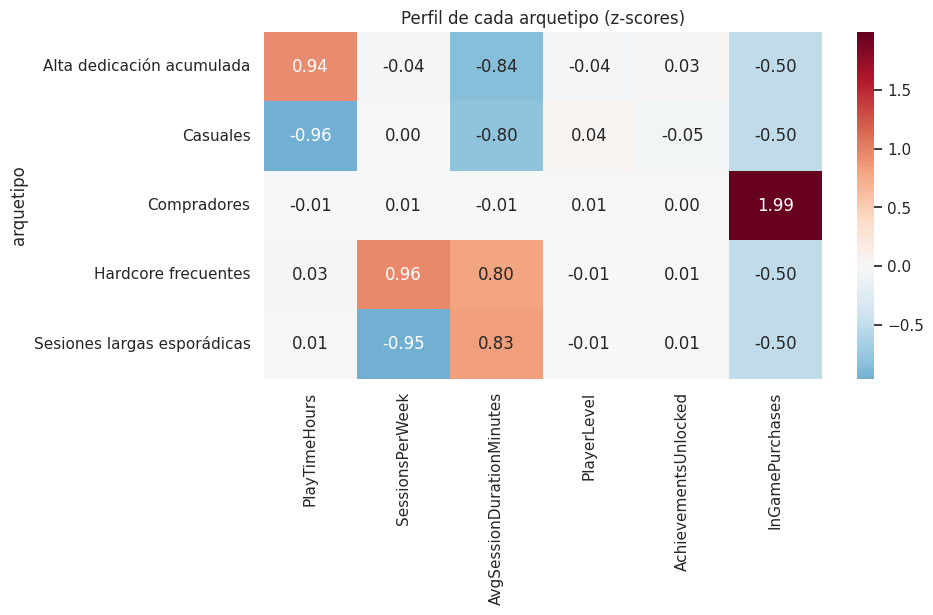

In [7]:
# Nombres asignados por reglas (reproducible aunque cambie la numeración de clusters)
names = {}
p = prof.copy()
names[p.InGamePurchases.idxmax()] = 'Compradores'
rest = p.drop(index=p.InGamePurchases.idxmax())
names[rest.SessionsPerWeek.idxmax()] = 'Hardcore frecuentes'
rest = rest.drop(index=rest.SessionsPerWeek.idxmax())
names[rest.SessionsPerWeek.idxmin()] = 'Sesiones largas esporádicas'
rest = rest.drop(index=rest.SessionsPerWeek.idxmin())
names[rest.PlayTimeHours.idxmax()] = 'Alta dedicación acumulada'
rest = rest.drop(index=rest.PlayTimeHours.idxmax())
names[rest.index[0]] = 'Casuales'
names = {int(k): v for k, v in names.items()}
df['arquetipo'] = df.cluster.map(names)
print(names)

z = pd.DataFrame(X, columns=feats); z['arquetipo'] = df.arquetipo.values
plt.figure(figsize=(9,4.5))
sns.heatmap(z.groupby('arquetipo').mean(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Perfil de cada arquetipo (z-scores)'); plt.show()

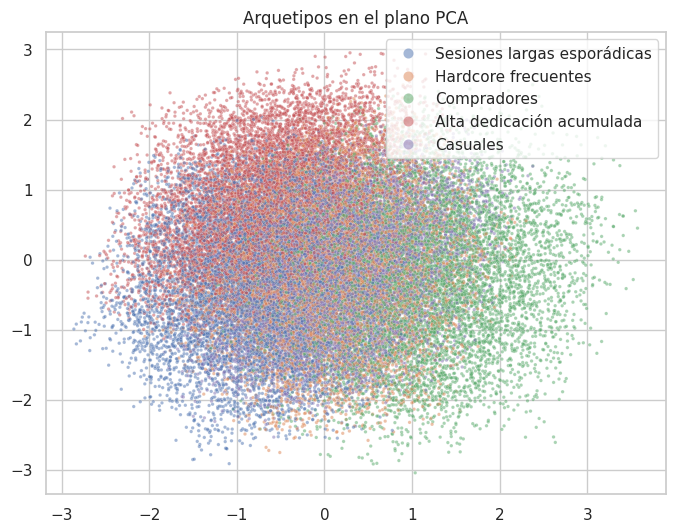

In [8]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=df.arquetipo, s=6, alpha=.5)
plt.title('Arquetipos en el plano PCA'); plt.legend(markerscale=3); plt.show()

In [9]:
# Perfilado con variables NO usadas para agrupar
for c in ['EngagementLevel','Gender','Location','GameGenre','GameDifficulty']:
    print(c); display((pd.crosstab(df.arquetipo, df[c], normalize='index')*100).round(1))

EngagementLevel


EngagementLevel,High,Low,Medium
arquetipo,,,
Alta dedicación acumulada,5.2,35.3,59.5
Casuales,6.0,33.5,60.5
Compradores,26.5,25.3,48.1
Hardcore frecuentes,83.7,3.3,13.0
Sesiones largas esporádicas,6.9,31.8,61.2


Gender


Gender,Female,Male
arquetipo,,
Alta dedicación acumulada,39.9,60.1
Casuales,40.4,59.6
Compradores,39.5,60.5
Hardcore frecuentes,41.2,58.8
Sesiones largas esporádicas,39.7,60.3


Location


Location,Asia,Europe,Other,USA
arquetipo,,,,
Alta dedicación acumulada,20.7,29.2,9.7,40.4
Casuales,19.5,30.8,10.2,39.5
Compradores,20.6,30.4,9.5,39.5
Hardcore frecuentes,20.0,29.5,9.8,40.7
Sesiones largas esporádicas,20.3,30.0,10.0,39.8


GameGenre


GameGenre,Action,RPG,Simulation,Sports,Strategy
arquetipo,,,,,
Alta dedicación acumulada,21.0,20.6,20.2,19.2,19.0
Casuales,19.8,20.2,19.7,20.3,20.0
Compradores,19.3,19.6,20.0,20.2,20.9
Hardcore frecuentes,20.3,19.3,19.7,20.6,20.1
Sesiones largas esporádicas,20.0,19.7,20.0,20.2,20.1


GameDifficulty


GameDifficulty,Easy,Hard,Medium
arquetipo,,,
Alta dedicación acumulada,49.9,20.0,30.2
Casuales,50.3,19.6,30.1
Compradores,49.7,19.9,30.4
Hardcore frecuentes,50.3,19.9,29.8
Sesiones largas esporádicas,49.9,20.6,29.6


## Evaluación

In [10]:
# Estabilidad: ARI entre el modelo completo y modelos ajustados en remuestreos bootstrap
rng = np.random.RandomState(0); aris = []
for i in range(20):
    b = rng.choice(len(X), len(X), replace=True)
    kb = KMeans(K, n_init=5, random_state=i).fit(X[b])
    aris.append(adjusted_rand_score(km.labels_, kb.predict(X)))
print(f'ARI medio = {np.mean(aris):.2f} ± {np.std(aris):.2f}')
print('Silhouette final:', round(silhouette_score(X, km.labels_, sample_size=10000, random_state=RS), 3))

ARI medio = 0.42 ± 0.11
Silhouette final: 0.145


**Conclusiones**
- **Estructura débil:** el silhouette (~0.14) indica grupos que se solapan. Las variables son casi uniformes y poco correlacionadas, así que los arquetipos son una *partición útil* de un espacio continuo, no grupos naturales.
- **Estabilidad moderada:** el ARI medio (~0.4) indica que las fronteras cambian entre remuestreos, aunque los rasgos centrales de cada arquetipo se mantienen.
- **Qué separa a los grupos:** frecuencia de sesiones, duración de sesión, horas totales y compra. `PlayerLevel` y `AchievementsUnlocked` casi no aportan.
- **Compras independientes de la actividad:** quien compra no juega más ni menos que el resto.
- **Limitación:** el dataset parece sintético o muy regular; conviene validar con datos reales antes de decidir algo de negocio.

## Arquetipos y estrategias sugeridas
| Arquetipo | Rasgo | Estrategia |
|---|---|---|
| Hardcore frecuentes | ~15 sesiones/sem., sesiones largas | Contenido avanzado, eventos competitivos, programa de embajadores |
| Sesiones largas esporádicas | ~4 sesiones/sem., sesiones largas | Recordatorios y recompensas semanales, contenido para sesión larga |
| Alta dedicación acumulada | Más horas totales, sesiones cortas | Contenido episódico y misiones cortas, pase de temporada |
| Casuales | Pocas horas y sesiones cortas | Onboarding, retención temprana, ofertas de bajo costo |
| Compradores | Compran, actividad promedio | Ofertas y bundles personalizados, VIP |

_Validar cada estrategia con pruebas A/B._

## Despliegue (guardar el modelo para Streamlit)

In [11]:
joblib.dump({'scaler': scaler, 'kmeans': km, 'features': feats, 'names': names}, 'modelo_clustering_jugadores.pkl')
nuevo = pd.DataFrame([{'PlayTimeHours': 10, 'SessionsPerWeek': 14, 'AvgSessionDurationMinutes': 120,
                       'PlayerLevel': 60, 'AchievementsUnlocked': 30, 'InGamePurchases': 0}])
m = joblib.load('modelo_clustering_jugadores.pkl')
c = m['kmeans'].predict(m['scaler'].transform(nuevo[m['features']]))[0]
print('Arquetipo:', m['names'][c])
import sklearn; print('scikit-learn:', sklearn.__version__)   # usa este número en requirements.txt

Arquetipo: Hardcore frecuentes
scikit-learn: 1.6.1
